<img src=https://courseware.decoded.com/images/decoded/logo-decoded.png align=left width=100px/> 

# Statistics for Feature Selection in Machine Learning
---
<small>© COPYRIGHT 2026 DECODED LIMITED. ALL RIGHTS RESERVED. Web: https://decoded.com/ </small>

# Statistics in the context of feature selection

Now that we've introduced statistical concepts we'll now focus on some of the motivation behind why we might apply these in machine learning in particular we will looks at the ***feature selection*** process

Contrary to popular belief, adding more feature to your dataset doesn't always make your model better. In fact, adding irrelevant features can actually make your model worse and make model training more computationally expensive. This is where feature selection comes in.

This notebook continues the university-performance case study.

It uses:

- `university_cleaned.csv`

Place the CSV file in the same folder as this notebook before running it.

## The decision pathway

This notebook connects statistical exploration to the machine learning pipeline.

We will follow this sequence:

1. **Inspect data quality**
2. **Measure distribution shape** using skew and kurtosis
3. **Inspect normality visually** using Q–Q plots
4. **Gather statistical evidence** using Shapiro–Wilk and K–S diagnostics
5. **Decide whether to test a transformation**
6. **Use ANOVA or an F-test to assess feature relevance**


> Normality evidence informs transformation decisions.
>
> ANOVA and F-tests inform feature relevance.
>
> Neither should make the final decision alone.

## Why this matters at feature selection in machine learning

A numerical feature may be highly skewed and still be useful.

A feature may follow a normal-looking distribution and have little relationship with the target.

A statistically significant ANOVA result may also produce only a small practical improvement in prediction.

A responsible workflow therefore separates three questions:

| Question | Evidence |
|---|---|
| What shape does the feature have? | Histogram, skew, kurtosis and Q–Q plot |
| Is there evidence against normality? | Shapiro–Wilk and K–S diagnostic |
| Does the feature contain information about the target? | ANOVA, F-test and feature-selection score |
| Does the complete workflow generalise? | Test or validation performance |

## Learning outcomes

By the end of the notebook, you will be able to:

1. load, standardise and join two related datasets
2. distinguish distribution diagnostics from feature-selection tests
3. interpret skew and excess kurtosis
4. use a Q–Q plot to inspect departures from normality
5. interpret Shapiro–Wilk and K–S p-values cautiously
6. explain when normality matters and when it does not
7. compare distributions before and after Yeo–Johnson transformation
8. use one-way ANOVA to screen a categorical feature
9. use an F-test to rank processed features for a numerical target
10. place preprocessing and feature selection inside a leakage-safe pipeline
11. compare baseline, transformed and feature-selected models

<details>
<summary><strong>Facilitator guidance</strong></summary>

### Keep repeating these distinctions

- Skew, kurtosis and normality tests describe a distribution.
- They do not measure predictive usefulness.
- ANOVA and F-tests measure evidence of association with the target.
- They do not prove causation or guarantee model improvement.
- Test performance evaluates the complete workflow.

### Important misconception

Most machine learning algorithms do not require every input feature to be normally distributed.

For ANOVA and classical regression inference, normality relates more closely to within-group errors or model residuals than to every raw feature.

### Teaching approach

Before each code cell, ask learners to predict:

- what evidence they expect
- what decision the evidence could support
- what the evidence cannot prove

</details>

## Load and prepare the data

### Import the tools

SciPy provides the statistical tests and Q–Q plot functions used in this notebook.

In [36]:
from pathlib import Path

%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

from IPython.display import display

from sklearn.compose import ColumnTransformer
from sklearn.feature_selection import SelectPercentile, f_regression
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, PowerTransformer, StandardScaler


RANDOM_STATE = 42
ALPHA = 0.05

pd.set_option('display.max_columns', 50)
pd.set_option('display.float_format', lambda value: f'{value:,.4f}')

print('Setup complete.')

Setup complete.


### Load the existing CSV files

Let's recall the processed data file in section 1.

It uses the datasets already followed through the university case study.

In [37]:
university_data = pd.read_csv("universities_cleaned.csv")

In [38]:
# present the joined dataset

display(university_data.head())

,university_id,applications,accepted,enrolled,spend_per_student,spend_band_hint,student_satisfaction,research_score,staff_student_ratio,private,region,campus_type,funding_band,data_policy,graduation_rate,strong_outcome,programme,attendance_rate,engagement_score,submission_rate,regional_advisor,support_priority,annual_support_budget,target_engagement_score,target_student_satisfaction,acceptance_rate,enrolment_rate,high_acceptance,high_spend
0,UNI0001,2874,1707,1273,"27,111.6700",Upper,74.4000,65.4000,12.4000,No,South,Campus,Low,UNI_2026,75.0000,1,data science,71.1000,62.5000,67.6000,Ben,Medium,90000,66.0000,67.0000,0.5939,0.7458,High acceptance,High spend
1,UNI0002,17253,10971,3729,"17,358.6400",Middle,74.7000,60.1000,10.4000,No,South,City,Low,UNI_2026,67.9000,0,MECHANICAL ENGINEERING,56.2000,58.2000,59.8000,Ben,Medium,90000,66.0000,67.0000,0.6359,0.3399,High acceptance,Low spend
2,UNI0003,14746,4041,1368,"21,362.4500",Middle,60.6000,66.0000,11.1000,No,East,City,Medium,UNI_2026,67.6000,0,artificial intelligence,60.5000,46.2000,53.3000,Chloe,Medium,98000,65.0000,68.0000,0.2740,0.3385,Low acceptance,High spend
3,UNI0004,10216,4966,1608,"4,500.0000",Lower,67.2000,55.2000,15.2000,No,West,Mixed,High,UNI_2026,57.9000,0,MECHANICAL ENGINEERING,52.8000,45.0000,49.5000,Daniel,Low,82000,64.0000,66.0000,0.4861,0.3238,Low acceptance,Low spend
4,UNI0005,10093,2489,1516,"11,483.7400",Lower,86.4000,84.2000,6.7000,Yes,South,City,High,UNI_2026,84.7000,1,ARTIFICIAL INTELLIGENCE,67.7000,85.6000,73.1000,Ben,Medium,90000,66.0000,67.0000,0.2466,0.6091,Low acceptance,Low spend


## Define the machine learning question

### Select the target

The modelling question is:

> Can university, programme, participation and regional-support features help predict `engagement_score`?

This is a regression problem because the target is numerical.

In [39]:
# First , we define a target column
TARGET_COLUMN = 'engagement_score'

# Flag if target column is not found in the dataset 
if TARGET_COLUMN not in university_data.columns:
    raise KeyError(
        f'{TARGET_COLUMN!r} was not found. '
        f'Available columns: {university_data.columns.tolist()}'
    )

# Another guardrail: force the target column to be numeric
university_data[TARGET_COLUMN] = pd.to_numeric(
    university_data[TARGET_COLUMN],
    errors='coerce',
)

model_data = university_data.dropna(
    subset=[TARGET_COLUMN]
).copy()

print('Rows available for modelling:', len(model_data))
display(model_data[TARGET_COLUMN].describe().to_frame('engagement_score'))

Rows available for modelling: 240


,engagement_score
count,240.0000
mean,58.2596
std,9.3209
min,40.0000
25%,51.6000
50%,58.1000
75%,63.3500
max,85.6000


### Separate training and test data

All transformation, normality investigation and feature-selection decisions must use the training data.

The test data represents unseen information.

In [ ]:
# Split the dataset into training and test sets
X_raw = model_data.drop(columns=[TARGET_COLUMN])
y = model_data[TARGET_COLUMN].copy()

# Split the dataset into training and test sets
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X_raw,
    y,
    test_size=0.25,
    random_state=RANDOM_STATE,
)

print('Training features:', X_train_raw.shape)
print('Test features:', X_test_raw.shape)

Training features: (180, 28)
Test features: (60, 28)


## Describe distribution shape of numerical features

### Skew and kurtosis 

**Skew** describes asymmetry. It is also referred as the third moment

- Positive skew means the longer tail extends towards larger values.
- Negative skew means the longer tail extends towards smaller values.
- A value near zero indicates a more balanced distribution.

**Excess kurtosis** helps describe tail weight. It is also referred as the fourth moment.

- A normal distribution has excess kurtosis close to zero.
- A positive value suggests heavier tails.
- A large positive value suggests that extreme observations deserve attention.

These values are diagnostic signals, not feature-removal rules.

In [41]:
# Use EDA report to help us out 
from data_profiling import ProfileReport

# Generate EDA report for training features

eda_report = ProfileReport(
    X_train_raw,
    title="Training Features EDA Report",
    pool_size=1
)

eda_report.to_file(
    "eda_report.html"
)

print("EDA report saved as eda_report.html")



Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]

100%|██████████| 28/28 [00:00<00:00, 297.88it/s]


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

Export report to file:   0%|          | 0/1 [00:00<?, ?it/s]

EDA report saved as eda_report.html


## Working interpretation guide

| Measure | Working interpretation |
|---|---|
| Absolute skew below 0.5 | Roughly symmetric |
| Absolute skew from 0.5 to below 1 | Moderate asymmetry |
| Absolute skew of 1 or more | Strong asymmetry: investigate |
| Excess kurtosis between -1 and 1 | Closer to normal-like tail weight |
| Excess kurtosis above 1 | Heavier tails |
| Excess kurtosis well above 3 | Inspect extreme observations |

These thresholds help prioritise investigation. They are not universal pass or fail criteria.

## Use Q–Q plots to inspect normality

### What is a Q–Q plot?

A Q–Q plot compares the observed feature values with the values expected from a theoretical normal distribution.

Look for:

- points following the diagonal line: closer agreement with normality
- a curved pattern: skew or another systematic difference
- deviations at both ends: heavier or lighter tails
- isolated points far from the line: possible extreme observations

A Q–Q plot is a visual diagnostic, not a hypothesis test.

In [42]:
# Let's say we want to investigate a few features to check for their normality

# Loop approach - more advanced 
priority_features = [
    "attendance_rate",
    "submission_rate",
    "spend_per_student",
]

print("Features selected for Q–Q plots:")

for feature in priority_features:
    print("-", feature)


Features selected for Q–Q plots:
- attendance_rate
- submission_rate
- spend_per_student


In [43]:
available_features = []

for feature in priority_features:
    if feature not in X_train_raw.columns:
        print(f"{feature} was not found and will be skipped.")
        continue

    numeric_values = pd.to_numeric(
        X_train_raw[feature],
        errors="coerce"
    ).dropna()

    available_features.append(feature)


In [44]:

print("\nFeatures ready for plotting:")

for feature in available_features:
    print("-", feature)


Features ready for plotting:
- attendance_rate
- submission_rate
- spend_per_student


### Create the QQ-plot

A Q–Q plot requires two sets of values:

- **Theoretical quantiles:** values expected from a normal distribution
- **Observed quantiles:** the ordered values from our feature

`stats.probplot()` calculates both sets of values.


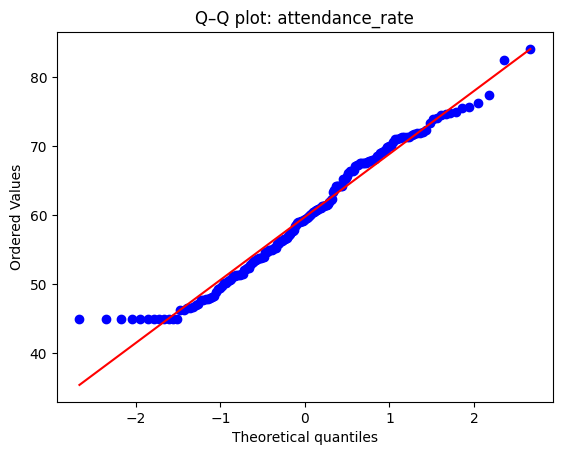

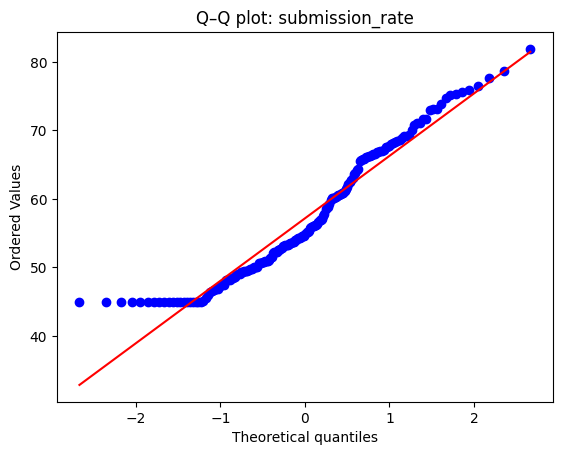

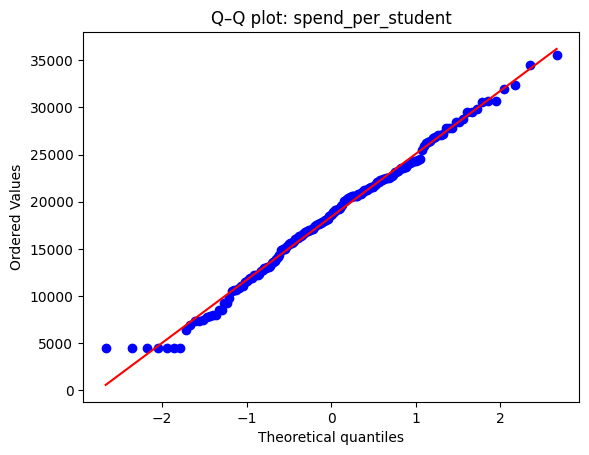

In [46]:
from scipy import stats

for feature in priority_features:

    values = X_train_raw[feature].dropna()

    stats.probplot(
        values,
        dist="norm",
        plot=plt
    )

    plt.title(f"Q–Q plot: {feature}")
    plt.show()


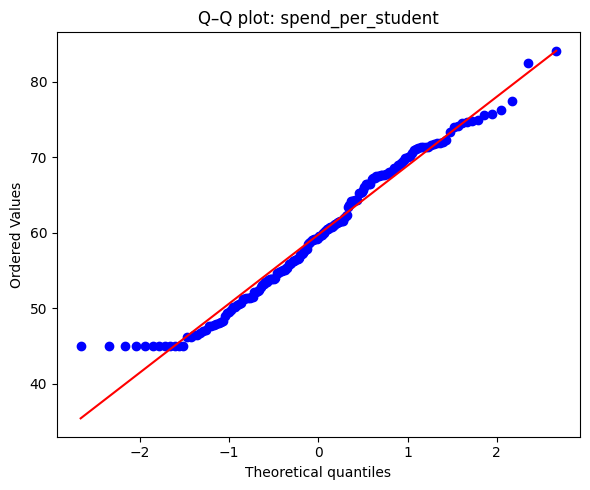

In [47]:
# Show how to create a QQ-plot for one single feature

values = X_train_raw["attendance_rate"].dropna()
plt.figure(figsize=(6, 5))
stats.probplot(
        values,
        dist='norm',
        plot=plt,
    )
plt.title(f'Q–Q plot: {feature}')
plt.tight_layout()
plt.show()


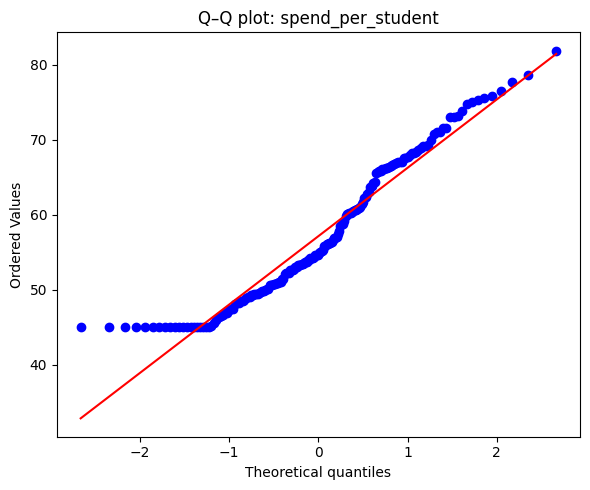

In [48]:
# Learners to practice with other two features: submission rate and enrolled

# Your code here
values = X_train_raw["submission_rate"].dropna()
plt.figure(figsize=(6, 5))
stats.probplot(
        values,
        dist='norm',
        plot=plt,
    )
plt.title(f'Q–Q plot: {feature}')
plt.tight_layout()
plt.show()

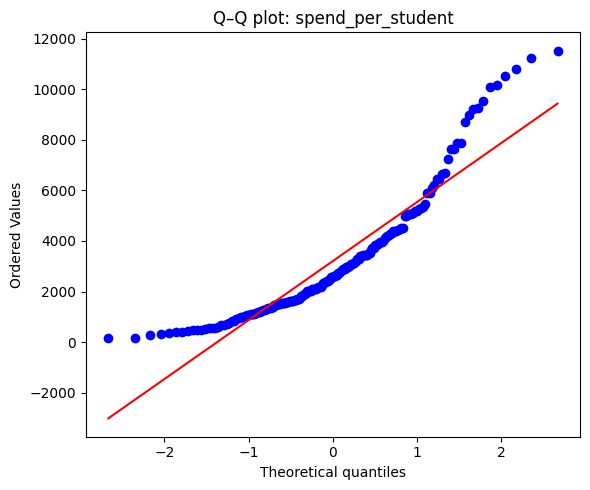

In [49]:
values = X_train_raw["enrolled"].dropna()
plt.figure(figsize=(6, 5))
stats.probplot(
        values,
        dist='norm',
        plot=plt,
    )
plt.title(f'Q–Q plot: {feature}')
plt.tight_layout()
plt.show()

### Q–Q plot discussion

For each feature, answer:

1. Do the middle observations follow the reference line?
2. Do the tails move away from the line?
3. Is the departure mainly caused by skew, heavy tails or isolated values?
4. Would a transformation be worth testing?
5. What information does the plot not provide about predictive relevance?

## Use Shapiro–Wilk and K–S diagnostics to test distribution

### The shared hypothesis

For both diagnostics, the working null hypothesis is:

> The tested values are consistent with a normal distribution.

Using an `\alpha` level of `0.05`:

- `p < 0.05`: evidence against normality
- `p >= 0.05`: insufficient evidence to reject normality

Do not translate `p >= 0.05` into proof that a feature is normal.

## Important cautions

### Shapiro–Wilk

- Useful for detecting departures from normality.
- With large samples, it may detect small and unimportant departures.
- With small samples, it may have limited power.
- This notebook limits the tested sample to 5,000 observations.

### Kolmogorov–Smirnov

The one-sample K–S test compares an observed distribution with a fully specified theoretical distribution.

In this notebook, values are standardised using their sample mean and standard deviation. Because these parameters are estimated from the same data, the classical K–S p-value is only an approximate teaching diagnostic.

Use the K–S result together with:

- the Q–Q plot
- skew
- kurtosis
- business context

Do not use the K–S result as an automatic transformation or removal rule.

In [50]:
feature = priority_features[0]

values = pd.to_numeric(
    X_train_raw[feature],
    errors="coerce"
).dropna()

print("Feature:", feature)
print("Number of values:", len(values))
print("Unique values:", values.nunique())

Feature: attendance_rate
Number of values: 180
Unique values: 129


The normality tests need:

- at least three observations
- some variation in the values
- no missing values

For large datasets, we use a sample of up to 5,000 values for the Shapiro–Wilk test.

In [ ]:
if len(values) < 3 or values.nunique() < 3:
    raise ValueError(
        "This feature does not contain enough variation for a normality test."
    )

if len(values) > 5000:
    tested_values = values.sample(
        5000,
        random_state=RANDOM_STATE
    )
else:
    tested_values = values

print("Values used in the tests:", len(tested_values))

Values used in the tests: 180


### Run the Shapiro–Wilk test

The Shapiro–Wilk test checks whether the values are consistent with a normal distribution.

It is sensitive to sample size. With a large dataset, even a small departure from normality may produce a low p-value.

In [ ]:
shapiro_statistic, shapiro_p_value = stats.shapiro(
    tested_values
)

print("Shapiro statistic:", round(shapiro_statistic, 4))
print("Shapiro p-value:", round(shapiro_p_value, 4))

Shapiro statistic: 0.9712
Shapiro p-value: 0.0009


In [ ]:
if shapiro_p_value < 0.05:
    print(
        "Evidence against normality. "
        "Inspect the distribution and consider testing a transformation."
    )
else:
    print(
        "There is insufficient evidence to reject normality."
    )

Evidence against normality. Inspect the distribution and consider testing a transformation.


## Prepare the feature for the K–S test

The K–S test compares the feature with a standard normal distribution.

A standard normal distribution has:

- a mean of `0`
- a standard deviation of `1`

We therefore standardise the feature before running the test.

In [ ]:
# So we first standardise the values to have a mean of 0 and a standard deviation of 1. 
# This is done by subtracting the mean and dividing by the standard deviation.
standardised_values = (
    tested_values - tested_values.mean()
) / tested_values.std(ddof=1)

# Print the mean and standard deviation of the standardised values to confirm they are 0 and 1, respectively.
print("Standardised mean:", round(standardised_values.mean(), 4))
print("Standardised standard deviation:", round(standardised_values.std(), 4))

Standardised mean: 0.0
Standardised standard deviation: 1.0


In [ ]:
# Now we can perform the Kolmogorov–Smirnov test to compare the distribution of the standardised values against a normal distribution.
ks_statistic, ks_p_value = stats.kstest(
    standardised_values,
    "norm"
)

print("K–S statistic:", round(ks_statistic, 4))
print("K–S p-value:", round(ks_p_value, 4))

K–S statistic: 0.0673
K–S p-value: 0.372


In [ ]:
if ks_p_value < 0.05:
    print(
        "Evidence that the feature differs from a normal distribution."
    )
else:
    print(
        "There is insufficient evidence to reject normality."
    )


There is insufficient evidence to reject normality.


> **Important limitation**
>
> The K–S p-value is approximate in this example because the mean and standard deviation were estimated from the same data being tested.
>
> Use the result alongside:
>
> - the histogram
> - the Q–Q plot
> - skew
> - kurtosis
> - the Shapiro–Wilk result

### What should we do next?

Do not transform or remove a feature using the p-value alone.

Consider testing a transformation when several pieces of evidence agree:

- the histogram is strongly asymmetric
- the Q–Q plot moves away from the reference line
- absolute skew is high
- excess kurtosis suggests heavy tails
- Shapiro–Wilk or K–S provides evidence against normality

The final decision should depend on whether the transformation improves the machine learning pipeline.

#### Optional stretch: repeat the tests for several features

In [ ]:
## optional 
## you can use a shorter loop to perform the tests for all three features 
# store the results in a DataFrame for easier comparison.
results = []

for feature in priority_features:
    values = pd.to_numeric(
        X_train_raw[feature],
        errors="coerce"
    ).dropna()

    if len(values) < 3 or values.nunique() < 3:
        continue

    tested_values = values.sample(
        min(len(values), 5000),
        random_state=RANDOM_STATE
    )

    shapiro_statistic, shapiro_p_value = stats.shapiro(
        tested_values
    )

    standardised_values = (
        tested_values - tested_values.mean()
    ) / tested_values.std(ddof=1)

    ks_statistic, ks_p_value = stats.kstest(
        standardised_values,
        "norm"
    )

    results.append(
        {
            "feature": feature,
            "shapiro_p_value": shapiro_p_value,
            "ks_p_value_approximate": ks_p_value,
            "skew": values.skew(),
            "excess_kurtosis": values.kurt()
        }
    )

normality_results = pd.DataFrame(results).set_index("feature")

display(normality_results)

,shapiro_p_value,ks_p_value_approximate,skew,excess_kurtosis
feature,,,,
attendance_rate,0.0009,0.3720,0.1618,-0.8181
submission_rate,0.0000,0.0268,0.5073,-0.7564
spend_per_student,0.2682,0.8779,-0.0498,-0.2758


## How to combine the evidence

Do not ask only, ‘Is the p-value below 0.05?’

Use a combined decision:

| Evidence | Possible interpretation |
|---|---|
| Straight Q–Q plot and small skew | Transformation may not be necessary |
| Curved Q–Q plot and strong skew | Test a transformation |
| Tail departures and high kurtosis | Investigate unusual observations or robust methods |
| Significant test but minor visual departure | Sample size may be detecting a small difference |
| Non-significant test but clear Q–Q departure | The sample may be too small to detect it reliably |

Normality diagnostics help decide what to **test next**. They do not decide whether a feature should be selected.

## Break 

You have completed:

- data preparation and joining
- train/test separation
- skew and kurtosis
- Q–Q plots
- Shapiro–Wilk testing
- K–S diagnostics

When you return, you will test whether transformation changes the evidence.

## Using higher moment to guide our transformation process on the target

### Create a transformation shortlist

A feature is shortlisted when it:

- is numerical
- has more than two unique values
- has absolute skew of at least 1

This creates a consistent starting rule while keeping the final decision open.

In [ ]:
# Set the skew theresold

SKEW_THRESHOLD = 1.0

print("Skew threshold:", SKEW_THRESHOLD)

Skew threshold: 1.0


#### Check the skewness of the target

Our target is `engagement_score`.

Before building a regression model, we should inspect whether the target is strongly skewed.

A strongly right-skewed target can cause a regression model to:

- focus too heavily on unusually large values
- produce errors with unequal spread
- struggle to represent the relationship using a straight line

We use the training target only so that the test data does not influence modelling decisions.

In [ ]:
target_name = "engagement_score"

# extract the target values and convert them to numeric, dropping any NaN values
target_values = pd.to_numeric(
    y_train,
    errors="coerce"
).dropna()

# perform a quick check on the target values to ensure they are suitable for modelling
print("Target:", target_name)
print("Number of values:", len(target_values))
print("Minimum value:", target_values.min())
print("Maximum value:", target_values.max())

Target: engagement_score
Number of values: 180
Minimum value: 40.0
Maximum value: 85.6


In [ ]:
target_skew = target_values.skew()
print("Target skew:", round(target_skew, 3))

Target skew: 0.277


In [ ]:
if abs(target_skew) < 0.5:
    print("The target is roughly symmetric.")

elif abs(target_skew) < 1.0:
    print("The target is moderately skewed.")

else:
    print(
        "The target is strongly skewed. "
        "A transformation may be worth testing."
    )


The target is roughly symmetric.


### View the target distribution

A histogram helps us see whether the skew value reflects:

- a long right tail
- a long left tail
- a small number of extreme values
- a concentration of values in one part of the scale

In [ ]:
plt.figure(figsize=(8, 4))

plt.hist(
    target_values,
    bins=20
)

plt.axvline(
    target_values.mean(),
    linestyle="--",
    label="Mean"
)

plt.axvline(
    target_values.median(),
    linestyle=":",
    label="Median"
)

plt.title("Distribution of graduation rate")
plt.xlabel("Graduation rate")
plt.ylabel("Number of records")
plt.legend()
plt.tight_layout()
plt.show()

/var/folders/q9/wc4_0qyx4xn17dfwb9vk_4140000gq/T/ipykernel_77128/3779573466.py:25: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


#### Use `log1p` for a right-skewed numerical target

`log1p` calculates:

`log(1 + value)`

It is a simple transformation that is particularly useful for a non-negative, right-skewed numerical target.

Adding `1` means it can safely transform values of zero.

For example:

- `0` becomes `log(1)`, which is `0`
- smaller values remain distinguishable
- larger values are compressed

This reduces the distance between unusually large values and the rest of the data.

#### Why is `log1p` useful?

`log1p` is simple, but it can make an important difference in regression.

It may help by:

- reducing strong positive skew
- limiting the influence of unusually large target values
- making relationships more linear
- producing more stable model errors
- helping the model focus on proportional differences

For example, the difference between engagement scores of `10` and `20` may be more meaningful proportionally than the difference between `80` and `90`.

However, `log1p` should be tested rather than applied automatically.

It is suitable only when the target values are zero or positive.

In [ ]:
if target_values.min() < 0:
    raise ValueError(
        "log1p cannot be used because the target contains "
        "values below zero."
    )

print("The target is non-negative, so log1p can be tested.")

The target is non-negative, so log1p can be tested.


In [ ]:
log_target_values = np.log1p(
    target_values
)

print("Original values:")
display(target_values.head())

print("Log-transformed values:")
display(log_target_values.head())

Original values:


95    58.4000
126   56.8000
120   50.1000
67    55.6000
101   59.4000
Name: engagement_score, dtype: float64

Log-transformed values:


95    4.0843
126   4.0570
120   3.9338
67    4.0360
101   4.1010
Name: engagement_score, dtype: float64

#### Compare skew before and after transformation

A successful transformation will often reduce the absolute skew.

The transformed target does not need to be perfectly normal.

The main question is whether it creates a more useful representation for the regression model.

In [ ]:
original_skew = target_values.skew()
transformed_skew = log_target_values.skew()

skew_comparison = pd.DataFrame(
    {
        "target_version": [
            "Original engagement score",
            "Log-transformed engagement score"
        ],
        "skew": [
            original_skew,
            transformed_skew
        ],
        "absolute_skew": [
            abs(original_skew),
            abs(transformed_skew)
        ]
    }
)

display(skew_comparison)

,target_version,skew,absolute_skew
0,Original graduation rate,0.2767,0.2767
1,Log-transformed graduation rate,-0.1384,0.1384


#### Should we use the transformed target?

Do not choose `log1p` only because it reduces skew.

Compare two regression approaches:

1. train the model using the original graduation rate
2. train the model using the log-transformed graduation rate

Convert transformed predictions back using `expm1`, then compare:

- mean absolute error
- root mean squared error
- R-squared
- residual plots
- interpretability

Keep the transformation only when it improves the complete modelling workflow.

### Using ANOVA to perform feature selection

#### Normality and ANOVA are connected differently

One-way ANOVA asks whether the mean target differs across groups.

For example:

> Is mean engagement score the same across all programmes?

The ANOVA assumptions relate to:

- independent observations
- the spread of the target within groups
- approximately normal errors or within-group residuals
- similar group variances

The raw categorical feature itself does not need to be normally distributed.

#### ANOVA hypotheses

**Null hypothesis:** all group mean engagement scores are equal.

**Alternative hypothesis:** at least one group mean differs.

At an alpha level of 0.05:

- `p < 0.05`: evidence that the feature separates at least some target means
- `p >= 0.05`: insufficient evidence of a mean difference

ANOVA does not identify which groups differ, prove causation or guarantee useful model performance.

In [ ]:
if 'programme' in model_data.columns:
    GROUP_COLUMN = 'programme'
elif 'region' in model_data.columns:
    GROUP_COLUMN = 'region'
else:
    GROUP_COLUMN = None

print('Categorical feature selected for one-way ANOVA:', GROUP_COLUMN)

Categorical feature selected for one-way ANOVA: programme


In [ ]:
from scipy import stats

# Ensure graduation_rate is numerical
university_data["graduation_rate"] = pd.to_numeric(
    university_data["graduation_rate"],
    errors="coerce"
)


In [ ]:

# Remove rows missing the group or target
anova_data = university_data[
    ["region", "graduation_rate"]
].dropna()


In [ ]:

# Create one graduation-rate array for each region
region_groups = [
    group["graduation_rate"].values
    for _, group in anova_data.groupby("region")
]


In [ ]:

# Run the one-way ANOVA
f_statistic, p_value = stats.f_oneway(*region_groups)

print(f"F-statistic: {f_statistic:.3f}")
print(f"p-value: {p_value:.4f}")



F-statistic: 1.566
p-value: 0.1984


#### Discussion

* How do we interpret the result?
* How should we consider the outcome of ANOVA test in our model building process?

### What have we done in the part? 

You have completed:

- distribution diagnostics
- transformation testing
- one-way ANOVA


### Connect all dots

We have applied statistical techniques to assist with feature selection and guide our transformation of target variable:


The complete logic is:

> **Normality diagnostics:** should we test another numerical representation?
>
> **ANOVA or F-test:** does this feature show individual evidence of association with the target?


### Success criteria

A strong recommendation:

- does not use normality as a feature-removal rule
- combines visual and statistical evidence
- explains the limitation of the K–S p-value used here
- distinguishes ANOVA significance from effect size
- distinguishes statistical significance from predictive usefulness
- recommends another validation step rather than claiming certainty

### End of the day quiz

1. What does a Q–Q plot show?
2. What is the null hypothesis in a normality test?
3. Does `p >= 0.05` prove normality?
4. Why is the K–S result in this notebook approximate?
5. Does a non-normal input feature have to be removed?
6. What question does one-way ANOVA answer?
7. Which ANOVA assumption can the Levene test help investigate?
8. How does `f_regression` support feature selection?
9. Why must the selector be inside the pipeline?
10. Which evidence makes the final feature decision?

<details>
<summary><strong>Exit-check answers</strong></summary>

1. It compares observed quantiles with theoretical normal quantiles.
2. The tested values are consistent with the specified normal distribution.
3. No. It means there is insufficient evidence to reject the null hypothesis.
4. The normal mean and standard deviation were estimated from the same sample.
5. No. Normality is not a universal input requirement for machine learning.
6. Whether mean target values differ across two or more groups.
7. Similarity of group variances.
8. It produces an individual F-statistic and p-value for each processed feature against the numerical target.
9. To prevent test or validation data from influencing feature-selection scores.
10. Distribution evidence, relevance evidence, domain knowledge and unseen-data model performance together.

</details>

## Final takeaway

Use the tools for different jobs:

| Tool | Main job in the machine learning modeling workflow |
|---|---|
| Skew | Measure asymmetry |
| Kurtosis | Investigate tail weight and extremes |
| Q–Q plot | Visually inspect departures from normality |
| Shapiro–Wilk | Test for evidence against normality |
| K–S diagnostic | Compare the standardised sample with a normal distribution, with parameter-estimation caution |
| One-way ANOVA | Compare mean target values across categories |


The aim is not to make every feature normal or retain every statistically significant feature.

The aim is to build a workflow whose decisions are explainable and supported by unseen-data performance.

---

## Additional Resources for further learning

If you want to explore these concepts further, here are curated resources organised by learning style:

### **Some more statistical theories**

**Visual Diagnostics:**
- [Understanding Q-Q Plots](https://en.wikipedia.org/wiki/Q%E2%80%93Q_plot) — Visual guide to interpreting Q-Q plots
- Seaborn documentation on `probplot` — For creating professional Q-Q plots

**Statistical Theory:**
- Shapiro-Wilk Test ([Wikipedia](https://en.wikipedia.org/wiki/Shapiro%E2%80%93Wilk_test))
- Anderson-Darling Test for heavy-tailed distributions

**Data Transformation:**
- Box-Cox Transformation ([SciPy documentation](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.boxcox.html))
- Yeo-Johnson Transformation (works with negative values, unlike Box-Cox)

**Non-Parametric Alternatives:**
- Mann-Whitney U Test (alternative to independent t-test)
- Kruskal-Wallis Test (alternative to one-way ANOVA)
- Spearman's Rank Correlation (alternative to Pearson correlation)


### **Interactive Visualisations (Learn by Playing)**

These tools let you adjust parameters and see distributions change in real-time:

- **Seeing Theory** (Interactive probability explorer) — https://seeing-theory.brown.edu/
  - Hands-on sandbox for understanding distributions visually
  - Try: "Probability Distributions" section to see how parameters affect shape

- **3Blue1Brown: Essence of Statistics** (YouTube playlist) — https://www.youtube.com/playlist?list=PLZHQObOWTQDNU6R1_67000Dx_ZZJF34jO
  - Beautifully animated explanations of distributions and concepts
  - Best for visual learners who want intuition first

- **StatQuest with Josh Starmer** (YouTube) — https://www.youtube.com/c/joshstarmer
  - Clear explanations of normal distribution, log-transform, and skewness
  - Search: "Normal Distribution Explained", "Log Transform"

- **Desmos: Distribution Explorer** — https://www.desmos.com/calculator/xxyvptl7gy
  - Interactive calculator to experiment with normal distribution parameters

- **Probability Distribution App** (Wolfram Alpha) — https://www.wolframalpha.com/
  - Type "normal distribution" or "log normal distribution" to see plots

### **Python Libraries & Documentation**

Learn how to generate and analyse distributions in code:

**Core Libraries:**
- **NumPy Random Module** — https://numpy.org/doc/stable/reference/random/index.html
  - Comprehensive guide to generating random samples from distributions
  - Essential for simulating data like we did above

- **SciPy Stats** — https://docs.scipy.org/doc/scipy/reference/stats.html
  - 70+ probability distributions built-in
  - Functions for skewness, kurtosis, quantiles

- **Matplotlib Visualisation** — https://matplotlib.org/stable/gallery/index.html
  - See histograms, box plots, KDE plots in the gallery

- **Seaborn** — https://seaborn.pydata.org/examples.html
  - Statistical visualizations with less code

**Tutorials & Guides:**
- **Real Python: NumPy Tutorial** — https://realpython.com/numpy-tutorial/
- **Towards Data Science Blog** — https://towardsdatascience.com/
  - Search: "probability distributions", "log transform", "skewness"

### **Log-Transforms & Feature Engineering**

Specific resources for understanding and applying transformations:

- **Box-Cox Transformation Explained** — https://www.analyticsvidhya.com/blog/2021/05/box-cox-transformation-technique-for-non-normal-data/
  - Visual comparison of transformations before/after
  - When to use log, square-root, Box-Cox

- **Scikit-learn: Preprocessing** — https://scikit-learn.org/stable/modules/preprocessing.html
  - PowerTransformer and QuantileTransformer for handling skewed data
  - Code examples ready to use

- **Feature Engineering for Machine Learning** — https://www.oreilly.com/library/view/feature-engineering-for/9781491953235/
  - Book chapter on handling skewed data
  - Real-world examples

### **Business Case Studies (See It in Action)**

Learn how real companies use distribution analysis:

- **Harvard Business Review: The Flaw of Averages** — https://hbr.org/1998/11/the-flaw-of-averages
  - Original article by Sam Savage showing why means mislead executives
  - Business scenarios you'll encounter in your career

- **Pareto Principle (80/20 Rule)** — https://en.wikipedia.org/wiki/Pareto_principle
  - Why power law distributions matter in business
  - Customer lifetime value, revenue concentration, effort allocation

- **Power Law Distributions in SEO/Web Analytics** — Search "power law website traffic"
  - Real data: traffic on websites follows Pareto distribution
  - Implications for marketing strategy

### **Mathematical Foundations (Go Deeper)**

For those who want to understand the math behind the concepts:

- **Khan Academy: Statistics & Probability** — https://www.khanacademy.org/math/statistics-probability
  - Free, step-by-step lessons on distributions, variance, skewness
  - Best for building mathematical intuition

- **Brilliant.org: Probability Course** — https://brilliant.org/courses/probability/
  - Interactive problem-solving approach
  - Learn by doing

- **Paul's Online Math Notes: Calculus** — https://tutorial.math.lamar.edu/
  - For understanding integration in probability density functions
  - Helps explain why $E[X] = \int_{-\infty}^{\infty} x \cdot f(x) \, dx$

- **MIT OpenCourseWare: Introduction to Probability** — https://ocw.mit.edu/courses/res-6-012-introduction-to-probability-spring-2018/
  - Full university course, free
  - Rigorous but accessible

### **Quick Reference Cheat Sheets**

- **Distribution Cheat Sheet** — Search "probability distribution cheat sheet"
  - One-page summary of when to use which distribution
  - Parameters and properties at a glance

- **SciPy Distribution Reference** — https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.rv_continuous.html
  - Quick lookup for any distribution

---

